# 🍌 Đồ án phân loại mức độ chín của chuối — MobileNetV2 có giải thích đặc trưng

**Môn:** Nhập môn Thị giác máy tính · **Môi trường:** Kaggle GPU · **Nguồn dữ liệu:** [BananaImageBD, Mendeley Data v2](https://data.mendeley.com/datasets/ptfscwtnyz/2)

### Thí nghiệm giữ nguyên phân công

| Thí nghiệm | Chiến lược | So sánh |
|---|---|---|
| **MobileNet 1** | Pretrained ImageNet, khóa backbone, huấn luyện classifier | Transfer Learning cơ bản |
| **MobileNet 2** | Fine-tune các block cuối | Vai trò của fine-tuning |
| **MobileNet 3** | Fine-tune giống thí nghiệm 2, thêm augmentation **chỉ ở train** | Vai trò của tăng cường dữ liệu |

**Phần bổ sung bảo vệ đồ án:** (1) chia dữ liệu theo nhóm gần trùng để **giảm nguy cơ** leakage; (2) Feature Maps ở ba tầng; (3) Grad-CAM trên ảnh dự đoán đúng/sai; (4) RGB → grayscale ablation trên test với cùng checkpoint; (5) báo cáo hạn chế thực nghiệm.

- **Nhãn:** đọc từ các thư mục của ZIP, không mặc định số lớp theo ảnh phân công.
- **Checkpoint tốt nhất:** chọn bằng **Validation F1-Macro**, không dùng test để lựa chọn mô hình.
- **Tính liêm chính dữ liệu:** khi chỉ có ZIP augmented, filename/perceptual-hash **không thể đảm bảo** khôi phục chính xác ảnh gốc. Notebook ghi cảnh báo và xuất audit để báo cáo trung thực. Nếu có `source_id` chuẩn, khai báo `SOURCE_MAP_CSV` để chia theo nguồn đáng tin cậy hơn.
- **Đầu ra:** `banana_mobilenetv2_results.zip` chứa checkpoint, bảng thống kê, biểu đồ và file CSV.

## 0. Cách chạy trên Kaggle

1. **Add Input** ZIP có tên gần giống `Augmented Banana Ripeness Detection Dataset.zip`, hoặc thư mục ảnh đã giải nén.
2. **Settings → Accelerator → GPU**; bật Internet để tải MobileNetV2 pretrained ImageNet hoặc thêm file trọng số vào **Add Input** và khai báo `PRETRAINED_WEIGHT_PATH`.
3. Nếu có bảng `path,source_id` đáng tin cậy nối từng ảnh augmented với ảnh gốc, điền đường dẫn CSV vào **`SOURCE_MAP_CSV`**. Nếu không có, notebook sẽ dùng *heuristic grouping*, lưu kết quả kiểm tra và cảnh báo các hạn chế.
4. **Run All**, sau đó **Save Version → Save & Run All (Commit)** để giữ checkpoint. Tải file ZIP kết quả từ **Output**.

**Quan trọng:** Dataset phát hành dưới dạng augmented có nguy cơ ảnh gần giống xuất hiện ở các tập khác nhau. Chia nhóm bằng hash và tên file giúp giảm rủi ro, nhưng **không thay thế được việc chia theo ID ảnh gốc**. Không nên tuyên bố kiểm thử độc lập tuyệt đối nếu chưa có ID nguồn hoặc tập ảnh gốc riêng.

## 1. Import thư viện và cấu hình

In [1]:
import os, re, json, random, shutil, zipfile, warnings, hashlib, time
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.models import MobileNet_V2_Weights
from IPython.display import display

# ========== CẤU HÌNH KAGGLE ==========
SEED = 42
INPUT_ROOT = Path('/kaggle/input') if Path('/kaggle/input').exists() else Path('/mnt/data')
WORK_ROOT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('/mnt/data')
DATA_SOURCE = None                 # Ví dụ: '/kaggle/input/banana/banana.zip' hoặc một thư mục
PRETRAINED_WEIGHT_PATH = None      # File ImageNet weights .pth nếu Kaggle Internet bị tắt
SOURCE_MAP_CSV = None              # (tùy chọn) CSV có cột path,source_id cho nguồn ảnh gốc
OUTPUT_DIR = WORK_ROOT / 'banana_mobilenetv2_results'
EXTRACT_DIR = WORK_ROOT / 'banana_ripeness_extracted'

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
VAL_RATIO = 0.15
TEST_RATIO = 0.15
EPOCHS = {'MobileNet 1': 6, 'MobileNet 2': 10, 'MobileNet 3': 10}
PATIENCE = 4
UNFREEZE_LAST_BLOCKS = 4
HEAD_LR = 1e-3
FINETUNE_LR = 1e-4
WEIGHT_DECAY = 1e-4

# Dùng hash gần giống ở mức thận trọng. Nếu nhiều ảnh khác nguồn nhưng hình giống nhau,
# chúng cũng có thể bị nhóm chung (hạn chế của hash, được báo cáo trong metadata).
NEAR_HASH_GROUP_THRESHOLD = 3  # khoảng cách Hamming dHash 64-bit, dùng trong cùng lớp
NEAR_HASH_AUDIT_THRESHOLD = 7  # tìm cặp đáng ngờ qua các split, không tự kết luận leakage
MAX_AUDIT_EXAMPLES = 100
GRADCAM_MAX_CORRECT = 3
GRADCAM_MAX_WRONG = 3
FEATURE_MAP_CHANNELS = 4

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for sub in ('checkpoints', 'figures', 'reports'):
    (OUTPUT_DIR / sub).mkdir(exist_ok=True)

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)
print('Thiết bị:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
print('Input:', INPUT_ROOT)
print('Output:', OUTPUT_DIR)

Thiết bị: cuda
GPU: Tesla T4
Input: /kaggle/input
Output: /kaggle/working/banana_mobilenetv2_results


## 2. Tìm ZIP / thư mục dữ liệu và tự phát hiện nhãn

In [2]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def zip_score(p):
    text = str(p).lower()
    score = 0
    if 'augment' in text: score += 5
    if 'ripeness' in text or 'ripness' in text: score += 5
    if 'detection' in text: score += 2
    if 'classifi' in text: score -= 12
    return score

def get_data_location():
    if DATA_SOURCE is not None:
        src = Path(DATA_SOURCE)
        if not src.exists():
            raise FileNotFoundError(f'DATA_SOURCE không tồn tại: {src}')
    else:
        zips = list(INPUT_ROOT.rglob('*.zip'))
        if zips:
            src = sorted(zips, key=lambda p: (zip_score(p), str(p)), reverse=True)[0]
            if zip_score(src) < 5:
                print('CẢNH BÁO: Chưa chắc ZIP tìm được là bộ ảnh chuối. ZIP được chọn:', src)
        else:
            src = INPUT_ROOT
    if src.is_file() and src.suffix.lower() == '.zip':
        print('Đang giải nén:', src)
        EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(src) as archive:
            # Chặn đường dẫn bất hợp lệ trong file nén
            dest = EXTRACT_DIR.resolve()
            for member in archive.infolist():
                member_path = (dest / member.filename).resolve()
                if member_path != dest and dest not in member_path.parents:
                    raise ValueError(f'ZIP chứa đường dẫn không an toàn: {member.filename}')
            archive.extractall(EXTRACT_DIR)
        return EXTRACT_DIR, src
    if src.is_dir():
        print('Đang dùng thư mục:', src)
        return src, src
    raise ValueError('DATA_SOURCE phải là thư mục hoặc file ZIP.')

def direct_image_count(folder):
    try:
        return sum(x.is_file() and x.suffix.lower() in IMAGE_EXTS for x in folder.iterdir())
    except (PermissionError, OSError):
        return 0

def find_class_root(root):
    candidates = []
    for current, dirs, _ in os.walk(root):
        dirs[:] = [d for d in dirs if not d.startswith('.') and d != '__MACOSX']
        parent = Path(current)
        children = []
        for d in dirs:
            folder = parent / d
            count = direct_image_count(folder)
            if count:
                children.append((folder, count))
        if 2 <= len(children) <= 30:
            total = sum(cnt for _, cnt in children)
            match = sum(int(token in str(parent).lower()) for token in ('augment', 'ripeness', 'ripness'))
            candidates.append((total, match, -len(parent.parts), parent, children))
    if not candidates:
        raise RuntimeError('Không tìm được cấu trúc <thư mục lớp>/<ảnh>. Kiểm tra ZIP đã thêm vào Kaggle.')
    candidates.sort(key=lambda item: (item[0], item[1], item[2]), reverse=True)
    return candidates[0][3], candidates[0][4]

DATA_ROOT, SOURCE_PATH = get_data_location()
CLASS_ROOT, CLASS_DIRS = find_class_root(DATA_ROOT)
class_names = sorted([p.name for p, _ in CLASS_DIRS], key=str.casefold)
class_to_idx = {name: i for i, name in enumerate(class_names)}
records = []
for name in class_names:
    folder = CLASS_ROOT / name
    for image_path in sorted(folder.iterdir()):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTS:
            try:
                with Image.open(image_path) as im:
                    im.verify()
                records.append({'path': str(image_path), 'class_name': name, 'label': class_to_idx[name]})
            except Exception as error:
                print('Bỏ qua ảnh lỗi:', image_path.name, error)

df = pd.DataFrame(records)
if len(class_names) < 2 or df.empty:
    raise RuntimeError('Dữ liệu phải có ít nhất 2 thư mục nhãn chứa ảnh hợp lệ.')
if df['class_name'].value_counts().min() < 10:
    raise RuntimeError('Mỗi lớp cần ít nhất 10 ảnh để chia train/validation/test.')

print('Thư mục lớp:', CLASS_ROOT)
print('SỐ LỚP TỰ PHÁT HIỆN:', len(class_names), ' | NHÃN:', class_names)
print('Tổng số ảnh:', len(df))
display(df.groupby('class_name').size().rename('Số ảnh').reset_index())
assert set(df['label']) == set(range(len(class_names)))

Đang dùng thư mục: /kaggle/input
Thư mục lớp: /kaggle/input/datasets/thinhng04/banana-dataset/Augmented Banana Ripeness Detection Dataset
SỐ LỚP TỰ PHÁT HIỆN: 4  | NHÃN: ['Green', 'Overripe', 'Ripe', 'Semi-ripe']
Tổng số ảnh: 2457


,class_name,Số ảnh
0,Green,636
1,Overripe,609
2,Ripe,603
3,Semi-ripe,609


## 3. Khảo sát và chia dữ liệu theo nhóm nguồn (giảm nguy cơ leakage)

**Chiến lược ưu tiên:** Nếu có CSV gồm `path,source_id`, nhóm theo ảnh gốc được cung cấp; nếu không, thử nhóm theo filename, pixel giống hệt và dHash gần giống **trong cùng nhãn**. Mọi split luôn dùng `GroupShuffleSplit` — **không fallback sang random stratified**.

Quy trình tạo `data_split_manifest.csv`, `split_leakage_audit.csv`, `run_metadata.json`. Kết quả vẫn chỉ là *đánh giá có kiểm soát rủi ro*, không phải chứng minh chắc chắn rằng mọi ảnh augmented cùng nguồn đều ở cùng split. Để kiểm chứng nghiêm ngặt, hãy dùng ảnh gốc + chia nhóm nguồn trước augmentation.

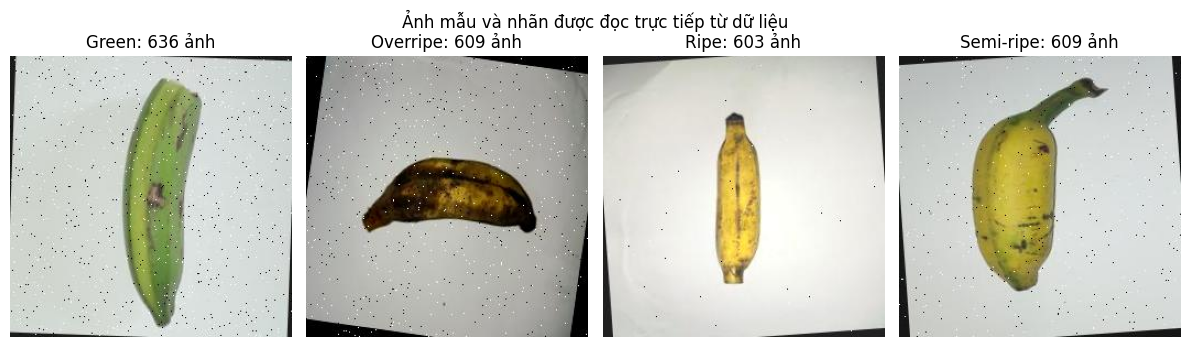

Đang phân tích hình ảnh và nhóm ảnh gần giống...
Cách nhóm: heuristic_filename_exact_pixel_dhash
Số nhóm có nhiều ảnh: 103


,class_name,Nhóm nguồn / lớp
0,Green,610
1,Overripe,553
2,Ripe,525
3,Semi-ripe,573


Chiến lược chia: GroupShuffleSplit with per-class distribution search: heuristic_filename_exact_pixel_dhash


/tmp/ipykernel_23/3961176471.py:197: UserWarning: Có 895 cặp dHash tương tự giữa các split (ngưỡng audit 7). Xem reports/split_leakage_audit.csv và kiểm tra bằng mắt; có thể cùng đối tượng nhưng ảnh khác nguồn.
  warnings.warn(f'Có {near_count} cặp dHash tương tự giữa các split (ngưỡng audit {NEAR_HASH_AUDIT_THRESHOLD}). '
/tmp/ipykernel_23/3961176471.py:200: UserWarning: Không có source_id ảnh gốc xác minh. Group split + dHash chỉ GIẢM NGUY CƠ leakage, không chứng minh độc lập tuyệt đối. Nên xin bản gốc và chia nguồn trước augmentation.
  warnings.warn('Không có source_id ảnh gốc xác minh. Group split + dHash chỉ GIẢM NGUY CƠ leakage, '


,Train,Val,Test
class_name,,,
Green,447,95,94
Overripe,428,93,88
Ripe,423,91,89
Semi-ripe,432,89,88


Số cặp nghi vấn gần trùng qua các tập: 895


In [3]:
fig, axes = plt.subplots(1, len(class_names), figsize=(max(11, 3 * len(class_names)), 3.5))
axes = np.atleast_1d(axes)
for i, name in enumerate(class_names):
    sample = df[df.class_name == name].iloc[0]
    with Image.open(sample.path) as image:
        axes[i].imshow(image.convert('RGB'))
    axes[i].set_title(f'{name}: {(df.class_name == name).sum()} ảnh')
    axes[i].axis('off')
fig.suptitle('Ảnh mẫu và nhãn được đọc trực tiếp từ dữ liệu')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'figures' / '01_class_samples.png', dpi=160, bbox_inches='tight')
plt.show()

# --------- Chuẩn hóa tên nguồn từ filename (heuristic, không tự xóa các số ID gốc) ---------
def infer_original_stem(path):
    stem = Path(path).stem.lower().strip()
    before = None
    while stem != before:
        before = stem
        stem = re.sub(r'(?i)([_\- ]+(?:aug(?:ment(?:ed)?)?|flip(?:ped)?|hflip|vflip|rot(?:ated|ation)?|brightness|bright|blur|noise|crop|zoom|copy)[_\- ]*\d*)$', '', stem)
        stem = re.sub(r'(?i)([_\- ]+\(copy(?: *\d+)?\))$', '', stem)
    return stem

# 64-bit difference hash; tạo hash chuẩn hóa theo biến thể lật ảnh.
# Khác nhau ít bit là một TÍN HIỆU gần giống, không xác nhận cùng nguồn tuyệt đối.
def dhash64(pil):
    arr = np.asarray(pil.convert('L').resize((9, 8), Image.Resampling.LANCZOS), dtype=np.int16)
    bits = (arr[:, 1:] > arr[:, :-1]).reshape(-1)
    out = 0
    for bit in bits:
        out = (out << 1) | int(bit)
    return out

def robust_dhash(pil):
    return min(dhash64(v) for v in (pil, ImageOps.mirror(pil)))

class DSU:
    def __init__(self, n):
        self.parent = list(range(n))
        self.size = [1] * n
    def find(self, x):
        while x != self.parent[x]:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x
    def union(self, a, b):
        a, b = self.find(a), self.find(b)
        if a != b:
            if self.size[a] < self.size[b]:
                a, b = b, a
            self.parent[b] = a
            self.size[a] += self.size[b]

# Đọc ảnh đúng một lần để tính hash và kiểm tra bản trùng lặp.
print('Đang phân tích hình ảnh và nhóm ảnh gần giống...')
df = df.reset_index(drop=True)
name_keys, exact_hashes, perceptual_hashes = [], [], []
for row in df.itertuples(index=False):
    with Image.open(row.path) as im:
        rgb = im.convert('RGB')
        # Hash pixel giúp phát hiện ảnh y hệt sau khi giải mã (khác JPEG metadata vẫn cùng pixel).
        pixel = np.asarray(rgb.resize((96, 96), Image.Resampling.BILINEAR))
        exact_hashes.append(hashlib.sha256(pixel.tobytes()).hexdigest())
        perceptual_hashes.append(robust_dhash(rgb))
    name_keys.append(f'{row.class_name}::{infer_original_stem(row.path)}')

df['stem_group'] = name_keys
df['pixel_sha256'] = exact_hashes
df['dhash64'] = [f'{h:016x}' for h in perceptual_hashes]

source_id_lookup = None
if SOURCE_MAP_CSV is not None:
    source_map = pd.read_csv(SOURCE_MAP_CSV, dtype=str)
    if not {'path', 'source_id'}.issubset(source_map.columns):
        raise ValueError('SOURCE_MAP_CSV phải có hai cột: path,source_id')
    source_map = source_map.dropna(subset=['path', 'source_id']).copy()
    source_map['path'] = source_map['path'].astype(str).str.replace('\\', '/', regex=False)
    if source_map.path.duplicated().any():
        raise ValueError('SOURCE_MAP_CSV có các path trùng nhau.')
    source_id_lookup = dict(zip(source_map.path, source_map.source_id))
    def source_id_for(path):
        rel = Path(path).relative_to(CLASS_ROOT).as_posix()
        candidates = (rel, str(Path(path).resolve()).replace('\\', '/'),
                      f'{Path(path).parent.name}/{Path(path).name}')
        for candidate in candidates:
            if candidate in source_id_lookup:
                return source_id_lookup[candidate]
        raise KeyError(f'Không tìm thấy source_id cho ảnh {rel} (đã bật SOURCE_MAP_CSV).')
    df['source_group'] = df.path.map(source_id_for)
    if df.groupby('source_group').label.nunique().max() > 1:
        raise ValueError('Có source_id bị gán nhiều nhãn khác nhau; hãy kiểm tra source map trước khi train.')
    GROUPING_METHOD = 'verified_source_id_csv'
else:
    dsu = DSU(len(df))
    for key_col in ('stem_group', 'pixel_sha256'):
        seen = {}
        for i, row in df.iterrows():
            # Chỉ nối trong cùng class; lỗi nhãn khác nhau được kiểm tra và cảnh báo bên dưới.
            key = (int(row.label), row[key_col])
            if key in seen:
                dsu.union(i, seen[key])
            else:
                seen[key] = i

    # So sánh dHash trong cùng lớp. 2.457 ảnh ~ 0.8 triệu cặp, chấp nhận được trên Kaggle.
    for label, indices in df.groupby('label').indices.items():
        indices = list(indices)
        for pos, a in enumerate(indices):
            ha = perceptual_hashes[a]
            for b in indices[pos + 1:]:
                if (ha ^ perceptual_hashes[b]).bit_count() <= NEAR_HASH_GROUP_THRESHOLD:
                    dsu.union(a, b)

    root_to_id = {}
    groups = []
    for i in range(len(df)):
        root = dsu.find(i)
        if root not in root_to_id:
            root_to_id[root] = f'heuristic_group_{len(root_to_id):05d}'
        groups.append(root_to_id[root])
    df['source_group'] = groups
    GROUPING_METHOD = 'heuristic_filename_exact_pixel_dhash'

# Một nguồn chỉ có thể thuộc một tập. Nếu số nhóm quá thấp, DỪNG và yêu cầu điều chỉnh có căn cứ.
class_group_counts = df.groupby('class_name').source_group.nunique()
if (class_group_counts < 3).any():
    raise RuntimeError(f'Không đủ 3 nhóm nguồn độc lập ở mỗi lớp: {class_group_counts.to_dict()}. '
                       'Kiểm tra mapping ảnh gốc hoặc giảm NEAR_HASH_GROUP_THRESHOLD (không tự fallback random).')
repeated_groups = int((df.groupby('source_group').size() > 1).sum())
print('Cách nhóm:', GROUPING_METHOD)
print('Số nhóm có nhiều ảnh:', repeated_groups)
display(class_group_counts.rename('Nhóm nguồn / lớp').reset_index())

# --------- Chia theo nhóm và cân bằng nhãn (chọn trong các thử nghiệm split ứng viên) ---------
def split_group(frame, fraction, seed, trials=200):
    labels = sorted(frame.label.unique().tolist())
    splitter = GroupShuffleSplit(n_splits=trials, test_size=fraction, random_state=seed)
    desired = frame.label.value_counts(normalize=True).reindex(labels, fill_value=0)
    best = None
    for train_idx, hold_idx in splitter.split(frame, frame.label, frame.source_group):
        train_part, hold_part = frame.iloc[train_idx], frame.iloc[hold_idx]
        if set(train_part.label) != set(labels) or set(hold_part.label) != set(labels):
            continue
        observed = hold_part.label.value_counts(normalize=True).reindex(labels, fill_value=0)
        drift = (observed - desired).abs().sum()
        size_drift = abs(len(hold_part) / len(frame) - fraction)
        score = float(drift + size_drift * 2)
        if best is None or score < best[0]:
            best = (score, train_idx, hold_idx)
    if best is None:
        raise RuntimeError('Không thể tạo GroupShuffleSplit đủ nhãn. Cần nhiều nhóm độc lập hơn ở từng lớp.')
    return frame.iloc[best[1]].copy(), frame.iloc[best[2]].copy()

train_val, test_df = split_group(df, TEST_RATIO, SEED)
train_df, val_df = split_group(train_val, VAL_RATIO / (1 - TEST_RATIO), SEED + 1)
train_df, val_df, test_df = [x.reset_index(drop=True) for x in (train_df, val_df, test_df)]
SPLIT_STRATEGY = 'GroupShuffleSplit with per-class distribution search: ' + GROUPING_METHOD
for aa, bb in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert set(aa.source_group).isdisjoint(set(bb.source_group)), 'Có source_group chung giữa các split.'
    assert set(aa.path).isdisjoint(set(bb.path)), 'Có path chung giữa các split.'

split_manifest = pd.concat([
    frame.assign(split=split_name) for split_name, frame in
    [('train', train_df), ('val', val_df), ('test', test_df)]
], ignore_index=True)
split_manifest.to_csv(OUTPUT_DIR / 'data_split_manifest.csv', index=False)

# Đối chiếu trùng pixel qua lớp khác (lỗi nhãn) và cặp nghi vấn gần giống qua các split.
collision_rows = []
for pixel_key, part in split_manifest.groupby('pixel_sha256'):
    if part.class_name.nunique() > 1:
        collision_rows.append({'issue': 'same_pixels_different_labels',
                               'img_a': part.iloc[0].path, 'img_b': part.iloc[-1].path,
                               'distance': 0})

# Audit các cặp hash gần giống across split (KHÔNG xem mọi cặp giống là leakage thật).
near_count = 0
for label, part in split_manifest.groupby('label'):
    paths = part.path.to_list()
    splits = part.split.to_list()
    hashes = [int(x, 16) for x in part.dhash64]
    for a in range(len(part)):
        for b in range(a + 1, len(part)):
            if splits[a] == splits[b]:
                continue
            dist = (hashes[a] ^ hashes[b]).bit_count()
            if dist <= NEAR_HASH_AUDIT_THRESHOLD:
                near_count += 1
                if len(collision_rows) < MAX_AUDIT_EXAMPLES:
                    collision_rows.append({'issue': 'near_hash_cross_split_check_manually',
                                           'img_a': paths[a], 'img_b': paths[b], 'distance': dist})

pd.DataFrame(collision_rows, columns=['issue', 'img_a', 'img_b', 'distance']).to_csv(
    OUTPUT_DIR / 'reports' / 'split_leakage_audit.csv', index=False
)
if near_count:
    warnings.warn(f'Có {near_count} cặp dHash tương tự giữa các split (ngưỡng audit {NEAR_HASH_AUDIT_THRESHOLD}). '
                  'Xem reports/split_leakage_audit.csv và kiểm tra bằng mắt; có thể cùng đối tượng nhưng ảnh khác nguồn.')
if GROUPING_METHOD.startswith('heuristic'):
    warnings.warn('Không có source_id ảnh gốc xác minh. Group split + dHash chỉ GIẢM NGUY CƠ leakage, '
                  'không chứng minh độc lập tuyệt đối. Nên xin bản gốc và chia nguồn trước augmentation.')

meta = {
    'dataset_source': 'https://data.mendeley.com/datasets/ptfscwtnyz/2',
    'chosen_data_source': str(SOURCE_PATH), 'class_root': str(CLASS_ROOT),
    'class_names': class_names, 'class_to_idx': class_to_idx,
    'num_classes': len(class_names), 'seed': SEED,
    'split_strategy': SPLIT_STRATEGY, 'grouping_method': GROUPING_METHOD,
    'grouped_repeated_source_ids': repeated_groups,
    'group_hash_threshold': NEAR_HASH_GROUP_THRESHOLD,
    'audit_hash_threshold': NEAR_HASH_AUDIT_THRESHOLD,
    'near_hash_cross_split_pairs': int(near_count),
    'same_pixel_conflicting_labels': len([x for x in collision_rows if x['issue'] == 'same_pixels_different_labels']),
    'split_counts': {k: len(v) for k, v in [('train', train_df), ('val', val_df), ('test', test_df)]},
    'limit_note': ('Source map verifies shared source IDs only if user-provided mapping is correct. '
                   'Image-hash grouping is heuristic; augmented originals cannot be reconstructed with certainty.')
}
(OUTPUT_DIR / 'run_metadata.json').write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding='utf8')
print('Chiến lược chia:', SPLIT_STRATEGY)
display(pd.DataFrame({k: v.class_name.value_counts().reindex(class_names, fill_value=0)
                      for k, v in [('Train', train_df), ('Val', val_df), ('Test', test_df)]}))
print('Số cặp nghi vấn gần trùng qua các tập:', near_count)

## 4. MobileNetV2 — chuẩn bị DataLoader và pretrained ImageNet

Cả ba thí nghiệm sử dụng **cùng train/validation/test** để so sánh công bằng.

- **MobileNet 1:** huấn luyện đầu phân loại mới, giữ nguyên backbone pretrained.
- **MobileNet 2:** khởi tạo từ checkpoint tốt nhất MobileNet 1, fine-tuning các block cuối.
- **MobileNet 3:** cũng khởi tạo từ checkpoint tốt nhất MobileNet 1, fine-tuning các block cuối **kèm tăng cường dữ liệu trên train**.

Augmentation hạn chế thay đổi Hue mạnh vì màu vỏ chuối là đặc trưng quan trọng để phân loại độ chín.


In [4]:
NORMALIZE = transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
base_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)), transforms.ToTensor(), NORMALIZE
])
augmentation_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=.5),
    transforms.RandomRotation(degrees=12),
    transforms.ColorJitter(brightness=.08, contrast=.08, saturation=.05),
    transforms.ToTensor(), NORMALIZE
])

class BananaImageDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        with Image.open(row.path) as img:
            img = img.convert('RGB')
            image = self.transform(img)
        return image, int(row.label)

def make_loader(frame, transform, shuffle=False):
    return DataLoader(
        BananaImageDataset(frame, transform), batch_size=BATCH_SIZE,
        shuffle=shuffle, num_workers=NUM_WORKERS, pin_memory=DEVICE.type=='cuda',
        persistent_workers=NUM_WORKERS > 0
    )

val_loader = make_loader(val_df, base_tf)
test_loader = make_loader(test_df, base_tf)

# Tải model ImageNet; nếu không có internet hãy cung cấp PRETRAINED_WEIGHT_PATH.
def create_imagenet_model():
    if PRETRAINED_WEIGHT_PATH:
        weights_path = Path(PRETRAINED_WEIGHT_PATH)
        if not weights_path.exists():
            raise FileNotFoundError(f'PRETRAINED_WEIGHT_PATH không tồn tại: {weights_path}')
        network = models.mobilenet_v2(weights=None)
        state = torch.load(weights_path, map_location='cpu', weights_only=False)
        if isinstance(state, dict) and 'state_dict' in state:
            state = state['state_dict']
        if isinstance(state, dict) and 'model_state_dict' in state:
            state = state['model_state_dict']
        network.load_state_dict(state, strict=True)  # weights ImageNet 1000 classes
        print('Đã nạp trọng số ImageNet từ:', weights_path)
    else:
        try:
            network = models.mobilenet_v2(weights=MobileNet_V2_Weights.IMAGENET1K_V1)
            print('Đã nạp pretrained MobileNetV2 (ImageNet)')
        except Exception as e:
            raise RuntimeError(
                'Không tải được trọng số MobileNetV2 đã huấn luyện trên ImageNet. '
                'Trong Kaggle hãy bật Internet ON, hoặc Add Input file .pth pretrained ImageNet '
                'và đặt biến PRETRAINED_WEIGHT_PATH. Không tự động chuyển sang random weights.'
            ) from e
    in_features = network.classifier[1].in_features
    network.classifier[1] = nn.Linear(in_features, len(class_names))
    return network

base_model = create_imagenet_model()
for p in base_model.features.parameters():
    p.requires_grad = False
base_model = base_model.to(DEVICE)
print('MobileNetV2 classifier output:', base_model.classifier[1].out_features)
assert base_model.classifier[1].out_features == len(class_names)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 128MB/s]


Đã nạp pretrained MobileNetV2 (ImageNet)
MobileNetV2 classifier output: 4


## 5. Huấn luyện, early stopping, lưu best checkpoint và đánh giá

In [5]:
def configure_finetuning(model, unfreeze_last_blocks=4):
    for p in model.features.parameters():
        p.requires_grad = False
    for block in list(model.features.children())[-unfreeze_last_blocks:]:
        for p in block.parameters():
            p.requires_grad = True
    for p in model.classifier.parameters():
        p.requires_grad = True
    return model

def freeze_inactive_batchnorm(model, head_only, n_unfreeze):
    # Ngăn BN trong backbone đã đóng băng cập nhật running statistics.
    if head_only:
        model.features.eval()
    else:
        for block in list(model.features.children())[:-n_unfreeze]:
            block.eval()

def run_epoch(model, loader, criterion, optimizer=None, scaler=None, head_only=False):
    is_train = optimizer is not None
    model.train(is_train)
    if is_train:
        freeze_inactive_batchnorm(model, head_only, UNFREEZE_LAST_BLOCKS)
    losses, targets, predictions = [], [], []
    for inputs, labels in loader:
        inputs = inputs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if is_train:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(is_train):
            with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type=='cuda'):
                logits = model(inputs)
                loss = criterion(logits, labels)
            if is_train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
        losses.append((loss.item(), len(labels)))
        targets.extend(labels.detach().cpu().numpy())
        predictions.extend(logits.argmax(1).detach().cpu().numpy())
    targets = np.asarray(targets)
    predictions = np.asarray(predictions)
    return {
        'loss':sum(loss*count for loss,count in losses)/sum(count for _,count in losses),
        'accuracy':accuracy_score(targets,predictions),
        'f1_macro':f1_score(targets,predictions,labels=np.arange(len(class_names)),average='macro',zero_division=0),
        'y_true':targets, 'y_pred':predictions
    }

def run_mobilenet_experiment(name, model, epochs, lr, augment=False, head_only=False):
    seed_everything(SEED)
    train_loader = make_loader(train_df, augmentation_tf if augment else base_tf, shuffle=True)
    trainable = [p for p in model.parameters() if p.requires_grad]
    print(f'\n{name} | Trainable parameters: {sum(p.numel() for p in trainable):,} | Augment={augment}')
    optimizer = torch.optim.AdamW(trainable, lr=lr, weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=.5, patience=2)
    scaler = torch.amp.GradScaler('cuda', enabled=DEVICE.type=='cuda')
    checkpoint_path = OUTPUT_DIR / 'checkpoints' / (name.lower().replace(' ', '_')+'_best.pth')
    history=[]
    best_score=-1
    best_epoch=0
    stagnant=0
    for epoch in range(1,epochs+1):
        tr = run_epoch(model, train_loader, criterion, optimizer, scaler, head_only=head_only)
        va = run_epoch(model, val_loader, criterion)
        scheduler.step(va['f1_macro'])
        history.append({
            'epoch':epoch, 'train_loss':tr['loss'], 'train_accuracy':tr['accuracy'], 'train_f1':tr['f1_macro'],
            'val_loss':va['loss'], 'val_accuracy':va['accuracy'], 'val_f1':va['f1_macro'],
            'lr':optimizer.param_groups[0]['lr']
        })
        score = va['f1_macro']
        if score > best_score + 1e-6:
            best_score = score
            best_epoch = epoch
            stagnant = 0
            torch.save({
                'arch':'mobilenet_v2', 'experiment':name, 'epoch':epoch,
                'class_names':class_names, 'class_to_idx':class_to_idx,
                'num_classes':len(class_names), 'seed':SEED,
                'best_val_f1_macro':float(score), 'best_val_accuracy':float(va['accuracy']),
                'model_state_dict':model.state_dict(),
                'optimizer_state_dict':optimizer.state_dict(),
                'scheduler_state_dict':scheduler.state_dict(),
                'pretrained':'ImageNet1K_V1', 'augmented_training':augment,
                'image_size':IMG_SIZE, 'mean':[.485,.456,.406], 'std':[.229,.224,.225]
            }, checkpoint_path)
        else:
            stagnant += 1
        print(f"{name} | epoch {epoch:02d}/{epochs} | train loss={tr['loss']:.4f} acc={tr['accuracy']:.4f} "
              f"| val loss={va['loss']:.4f} acc={va['accuracy']:.4f} F1={va['f1_macro']:.4f}")
        if stagnant >= PATIENCE:
            print(f'Early stopping, best epoch: {best_epoch}')
            break
    hist_df = pd.DataFrame(history)
    hist_df.to_csv(OUTPUT_DIR / 'reports' / (name.lower().replace(' ','_')+'_history.csv'),index=False)
    chk = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
    model.load_state_dict(chk['model_state_dict'],strict=True)
    model.to(DEVICE)
    te = run_epoch(model,test_loader,criterion)
    report_text = classification_report(te['y_true'],te['y_pred'],labels=np.arange(len(class_names)),target_names=class_names,zero_division=0)
    (OUTPUT_DIR / 'reports' / (name.lower().replace(' ','_')+'_test_report.txt')).write_text(report_text,encoding='utf8')
    return {
        'Thí nghiệm':name, 'Trainable params':sum(p.numel() for p in trainable),
        'Augmentation':augment, 'Best Epoch':best_epoch,
        'Val F1-Macro':float(best_score),
        'Val Accuracy':float(chk['best_val_accuracy']),
        'Test Accuracy':float(te['accuracy']), 'Test F1-Macro':float(te['f1_macro']),
        'Checkpoint':str(checkpoint_path)
    }, hist_df, te

def load_model_from_checkpoint(checkpoint_path):
    ckpt = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
    model = models.mobilenet_v2(weights=None)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, ckpt['num_classes'])
    model.load_state_dict(ckpt['model_state_dict'], strict=True)
    return model.to(DEVICE), ckpt

## 6. Chạy 3 thí nghiệm MobileNetV2

In [6]:
mobilenet_results = []
histories = {}
mobile_tests = {}

# MobileNet 1: pretrained ImageNet, đóng băng tất cả backbone.
row1, hist1, test1 = run_mobilenet_experiment(
    'MobileNet 1', base_model, epochs=EPOCHS['MobileNet 1'], lr=HEAD_LR,
    augment=False, head_only=True
)
mobilenet_results.append(row1)
histories['MobileNet 1'] = hist1
mobile_tests['MobileNet 1'] = test1

# MobileNet 2: tiếp tục từ baseline tốt nhất, fine-tune 4 block cuối.
model2, _ = load_model_from_checkpoint(row1['Checkpoint'])
configure_finetuning(model2, UNFREEZE_LAST_BLOCKS)
row2, hist2, test2 = run_mobilenet_experiment(
    'MobileNet 2', model2, epochs=EPOCHS['MobileNet 2'], lr=FINETUNE_LR,
    augment=False, head_only=False
)
mobilenet_results.append(row2)
histories['MobileNet 2'] = hist2
mobile_tests['MobileNet 2'] = test2

# MobileNet 3: cùng checkpoint baseline với MobileNet 2, thêm augmentation chỉ ở train.
model3, _ = load_model_from_checkpoint(row1['Checkpoint'])
configure_finetuning(model3, UNFREEZE_LAST_BLOCKS)
row3, hist3, test3 = run_mobilenet_experiment(
    'MobileNet 3', model3, epochs=EPOCHS['MobileNet 3'], lr=FINETUNE_LR,
    augment=True, head_only=False
)
mobilenet_results.append(row3)
histories['MobileNet 3'] = hist3
mobile_tests['MobileNet 3'] = test3

mobile_df = pd.DataFrame(mobilenet_results)
mobile_df.to_csv(OUTPUT_DIR / 'mobilenet_comparison.csv',index=False)
print('\n=== BẢNG SO SÁNH MOBILENETV2 ===')
display(mobile_df[['Thí nghiệm','Augmentation','Best Epoch','Trainable params','Val F1-Macro','Test Accuracy','Test F1-Macro']].style.format({
    'Val F1-Macro':'{:.4f}','Test Accuracy':'{:.4f}','Test F1-Macro':'{:.4f}'
}).highlight_max(subset=['Val F1-Macro','Test Accuracy','Test F1-Macro'],color='#dcefd9'))


MobileNet 1 | Trainable parameters: 5,124 | Augment=False
MobileNet 1 | epoch 01/6 | train loss=0.6829 acc=0.7832 | val loss=0.4407 acc=0.8533 F1=0.8558
MobileNet 1 | epoch 02/6 | train loss=0.3347 acc=0.8994 | val loss=0.3332 acc=0.8804 F1=0.8813
MobileNet 1 | epoch 03/6 | train loss=0.2760 acc=0.9168 | val loss=0.3132 acc=0.8832 F1=0.8846
MobileNet 1 | epoch 04/6 | train loss=0.2300 acc=0.9312 | val loss=0.2654 acc=0.9130 F1=0.9120
MobileNet 1 | epoch 05/6 | train loss=0.2190 acc=0.9283 | val loss=0.2554 acc=0.9158 F1=0.9152
MobileNet 1 | epoch 06/6 | train loss=0.1927 acc=0.9439 | val loss=0.2437 acc=0.9239 F1=0.9226

MobileNet 2 | Trainable parameters: 1,531,204 | Augment=False
MobileNet 2 | epoch 01/10 | train loss=0.2839 acc=0.8931 | val loss=0.2024 acc=0.9185 F1=0.9165
MobileNet 2 | epoch 02/10 | train loss=0.1016 acc=0.9630 | val loss=0.2006 acc=0.9239 F1=0.9238
MobileNet 2 | epoch 03/10 | train loss=0.0651 acc=0.9763 | val loss=0.1920 acc=0.9212 F1=0.9215
MobileNet 2 | epoch 

,Thí nghiệm,Augmentation,Best Epoch,Trainable params,Val F1-Macro,Test Accuracy,Test F1-Macro
0,MobileNet 1,False,6,5124,0.9226,0.9248,0.9235
1,MobileNet 2,False,5,1531204,0.9424,0.9610,0.9607
2,MobileNet 3,True,10,1531204,0.9503,0.9526,0.9525


## 7. Kết quả huấn luyện, chọn checkpoint theo validation và confusion matrix

**Chỉ số test được sử dụng để báo cáo cuối cùng, không dùng test để chọn model.**

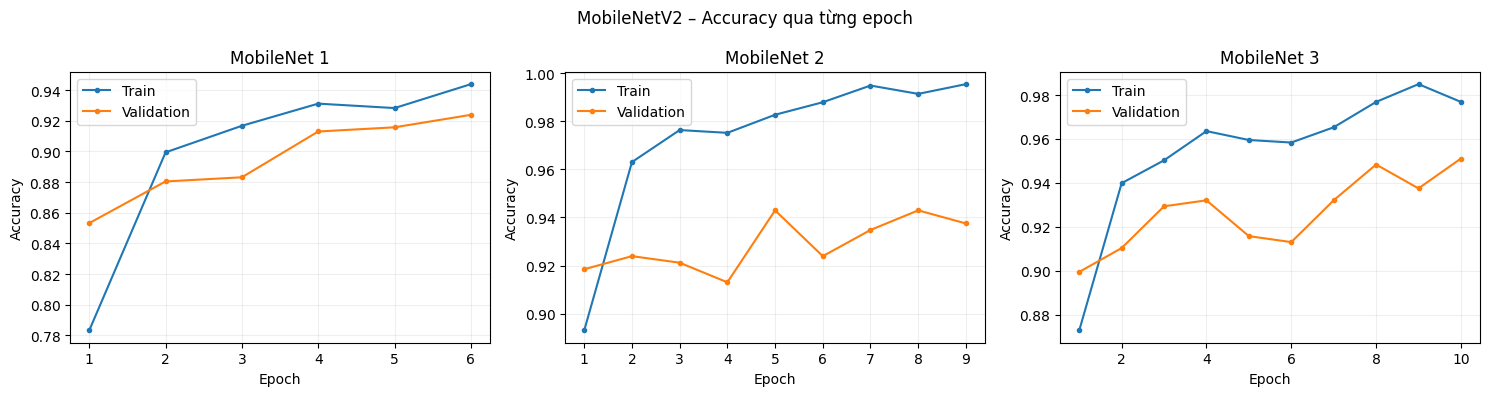

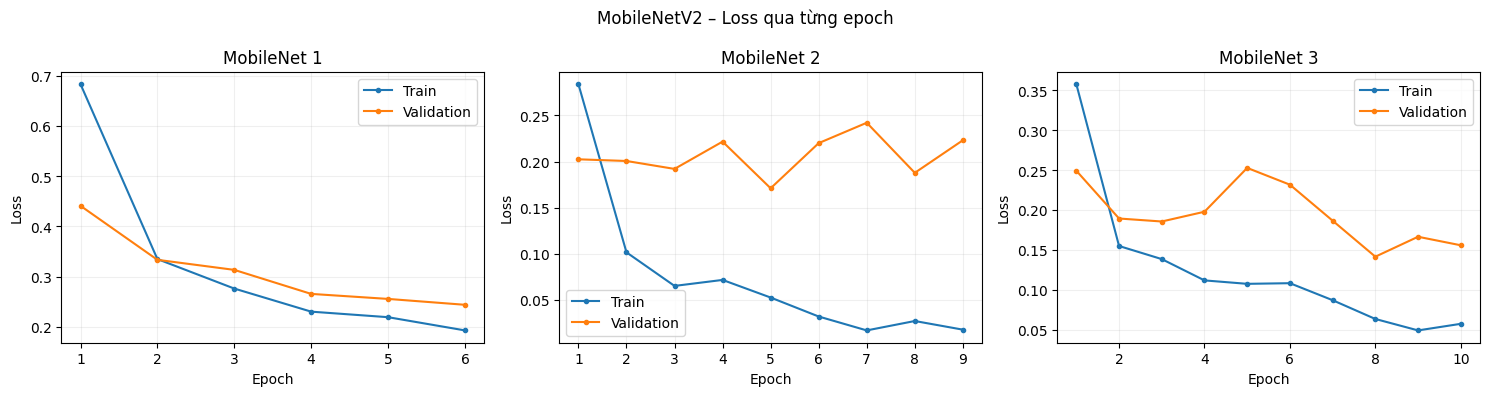

MÔ HÌNH MOBILENETV2 TỐT NHẤT (CHỌN THEO VALIDATION): MobileNet 3
Best checkpoint: /kaggle/working/banana_mobilenetv2_results/checkpoints/mobilenetv2_best_overall.pth
Test report:
               precision    recall  f1-score   support

       Green       1.00      0.96      0.98        94
    Overripe       1.00      0.99      0.99        88
        Ripe       0.89      0.98      0.93        89
   Semi-ripe       0.93      0.89      0.91        88

    accuracy                           0.95       359
   macro avg       0.95      0.95      0.95       359
weighted avg       0.95      0.95      0.95       359



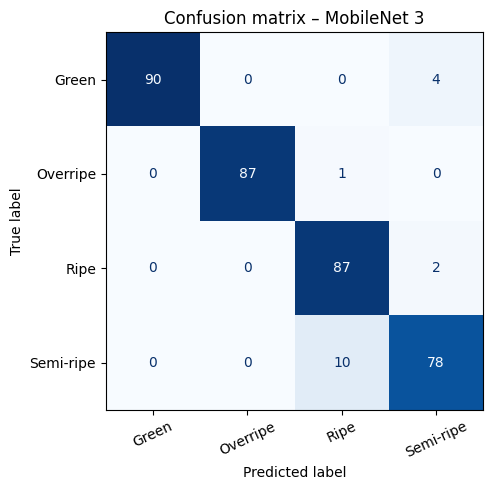

=== TỔNG HỢP 3 THÍ NGHIỆM MOBILENETV2 ===


,Thí nghiệm,Best Epoch,Augmentation,Val F1-Macro,Test Accuracy,Test F1-Macro
0,MobileNet 1,6,False,0.9226,0.9248,0.9235
1,MobileNet 2,5,False,0.9424,0.9610,0.9607
2,MobileNet 3,10,True,0.9503,0.9526,0.9525


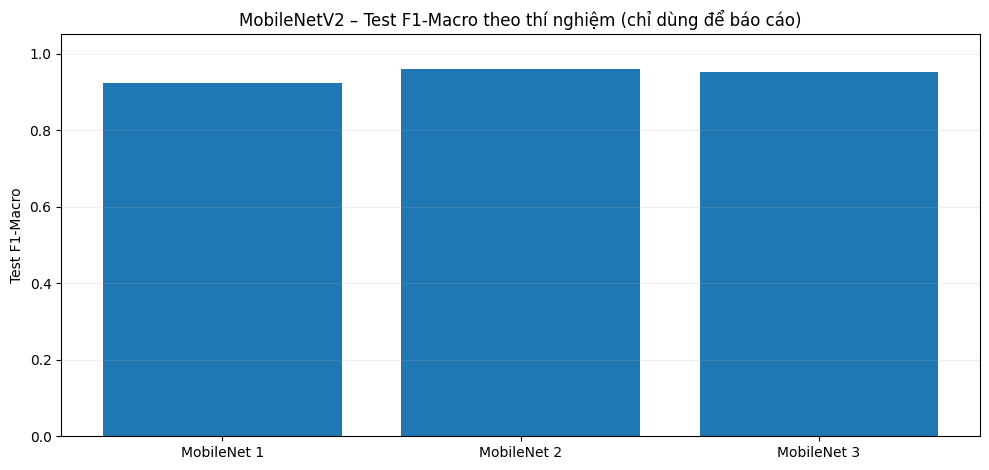

1217

In [7]:
for metric, ytitle, file_name in [
    ('accuracy', 'Accuracy', '04_mobilenet_accuracy.png'),
    ('loss', 'Loss', '05_mobilenet_loss.png')
]:
    fig, axes = plt.subplots(1, 3, figsize=(15,4), sharey=False)
    for ax, (name, hist) in zip(axes, histories.items()):
        ax.plot(hist['epoch'],hist[f'train_{metric}'],label='Train',marker='o',markersize=3)
        ax.plot(hist['epoch'],hist[f'val_{metric}'],label='Validation',marker='o',markersize=3)
        ax.set_title(name)
        ax.set_xlabel('Epoch')
        ax.set_ylabel(ytitle)
        ax.grid(alpha=.2)
        ax.legend()
    fig.suptitle(f'MobileNetV2 – {ytitle} qua từng epoch')
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR/'figures'/file_name,dpi=170,bbox_inches='tight')
    plt.show()

best_mobile_row = mobile_df.sort_values(['Val F1-Macro','Val Accuracy'], ascending=False).iloc[0]
best_mobile_name = best_mobile_row['Thí nghiệm']
best_mobile_path = Path(best_mobile_row['Checkpoint'])
best_overall_path = OUTPUT_DIR/'checkpoints'/'mobilenetv2_best_overall.pth'
shutil.copy2(best_mobile_path, best_overall_path)
print('MÔ HÌNH MOBILENETV2 TỐT NHẤT (CHỌN THEO VALIDATION):', best_mobile_name)
print('Best checkpoint:', best_overall_path)
print('Test report:\n', classification_report(mobile_tests[best_mobile_name]['y_true'],
    mobile_tests[best_mobile_name]['y_pred'], labels=np.arange(len(class_names)), target_names=class_names,zero_division=0))

fig, ax = plt.subplots(figsize=(6.3,5))
ConfusionMatrixDisplay.from_predictions(
    mobile_tests[best_mobile_name]['y_true'], mobile_tests[best_mobile_name]['y_pred'],
    labels=np.arange(len(class_names)), display_labels=class_names,
    cmap='Blues',xticks_rotation=25,colorbar=False,ax=ax
)
ax.set_title('Confusion matrix – '+best_mobile_name)
plt.tight_layout()
fig.savefig(OUTPUT_DIR/'figures'/'06_best_mobilenet_confusion_matrix.png',dpi=170,bbox_inches='tight')
plt.show()

# Bảng so sánh chỉ gồm 3 biến thể MobileNetV2.
summary = mobile_df[['Thí nghiệm', 'Best Epoch', 'Augmentation',
                     'Val F1-Macro', 'Test Accuracy', 'Test F1-Macro']].copy()
summary.to_csv(OUTPUT_DIR / 'mobilenet_summary.csv', index=False)
print('=== TỔNG HỢP 3 THÍ NGHIỆM MOBILENETV2 ===')
display(summary.style.format({
    'Val F1-Macro': '{:.4f}', 'Test Accuracy': '{:.4f}', 'Test F1-Macro': '{:.4f}'
}))

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(summary['Thí nghiệm'], summary['Test F1-Macro'])
ax.set_ylim(0, 1.05)
ax.set_title('MobileNetV2 – Test F1-Macro theo thí nghiệm (chỉ dùng để báo cáo)')
ax.set_ylabel('Test F1-Macro')
ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'figures' / '07_mobilenet_comparison.png', dpi=170, bbox_inches='tight')
plt.show()

meta.update({
    'best_mobilenet_by_validation': best_mobile_name,
    'best_mobilenet_checkpoint': str(best_overall_path)
})
(OUTPUT_DIR / 'run_metadata.json').write_text(
    json.dumps(meta, indent=2, ensure_ascii=False), encoding='utf8'
)


## 8. Load lại checkpoint tốt nhất và dự đoán ảnh kiểm thử

Đoạn này xác minh checkpoint từ đĩa có thể dùng lại để inference độc lập với mô hình trong RAM.

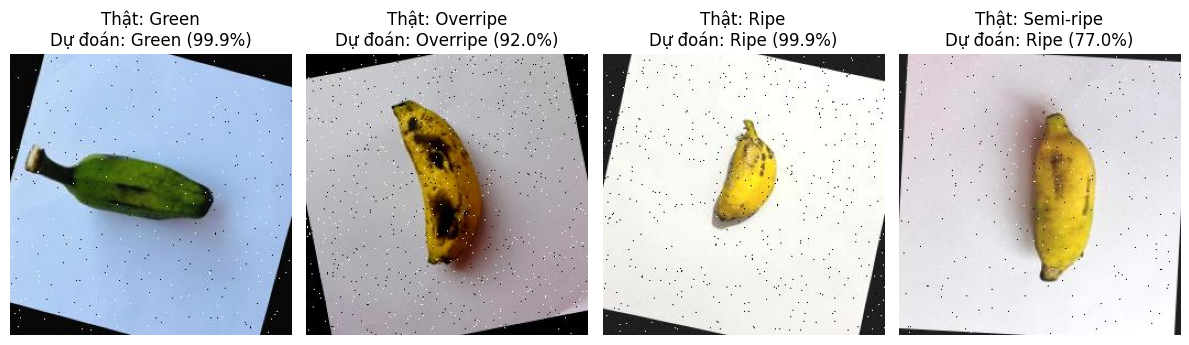

In [8]:
infer_model, infer_ckpt = load_model_from_checkpoint(best_overall_path)
infer_model.eval()
examples = test_df.groupby('class_name',group_keys=False).sample(n=1,random_state=SEED).reset_index(drop=True)
fig,axes=plt.subplots(1,len(examples),figsize=(max(12,3*len(examples)),3.5))
axes=np.atleast_1d(axes)
with torch.inference_mode():
    for ax,(_,row) in zip(axes,examples.iterrows()):
        with Image.open(row.path) as img:
            rgb=img.convert('RGB')
            tensor=base_tf(rgb).unsqueeze(0).to(DEVICE)
            proba=torch.softmax(infer_model(tensor),dim=1)[0]
            pred=int(proba.argmax().item())
            ax.imshow(rgb)
        ax.set_title(f"Thật: {row.class_name}\nDự đoán: {class_names[pred]} ({proba[pred]:.1%})")
        ax.axis('off')
plt.tight_layout()
fig.savefig(OUTPUT_DIR/'figures'/'08_inference_samples.png',dpi=170,bbox_inches='tight')
plt.show()

## 9. Feature Maps — xem các tầng của MobileNetV2 biểu diễn ảnh thế nào

Dùng forward hook để lấy activation tại **tầng đầu, tầng giữa, tầng cuối** của backbone. Mỗi channel là một feature map CNN học được (không phải đặc trưng HSV/HOG/LBP được lập trình sẵn). Minh họa chọn các channel có độ biến thiên không gian lớn nhất và chuẩn hóa độc lập từng channel để dễ nhìn; vì vậy **không so cường độ màu giữa các ô**.

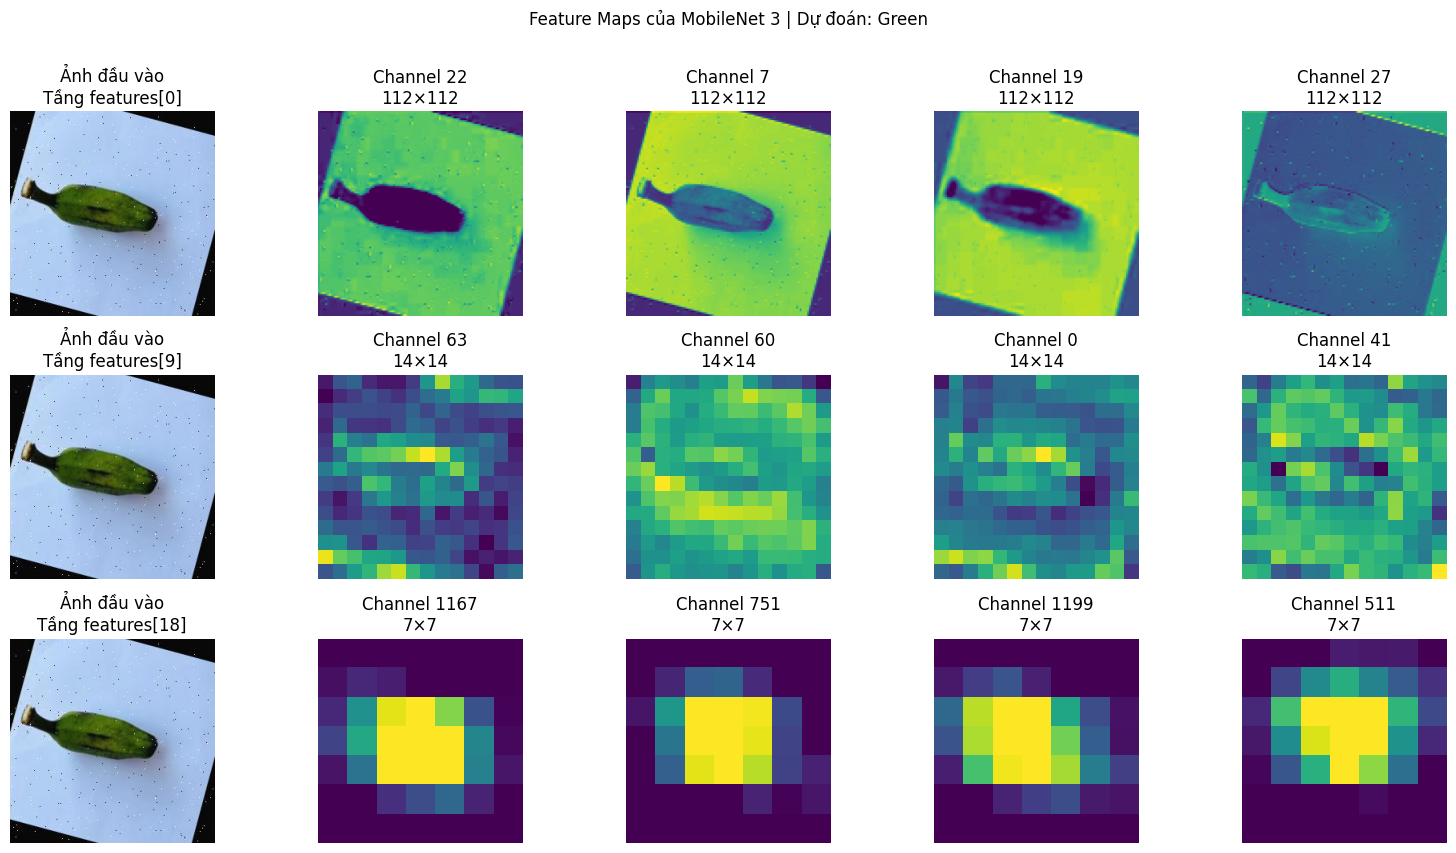

,layer,channel,feature_h,feature_w,activation_std
0,0,22,112,112,0.437024
1,0,7,112,112,0.259964
2,0,19,112,112,0.255794
3,0,27,112,112,0.185725
4,9,63,14,14,0.795516
5,9,60,14,14,0.784710
6,9,0,14,14,0.746512
7,9,41,14,14,0.723824
8,18,1167,7,7,2.240317
9,18,751,7,7,2.234720


In [9]:
def show_feature_maps(model, sample_path, max_maps=FEATURE_MAP_CHANNELS):
    model.eval()
    layer_indices = sorted(set([0, len(model.features) // 2, len(model.features) - 1]))
    activations = {}
    handles = []
    for layer_idx in layer_indices:
        def capture(module, inputs, outputs, layer_idx=layer_idx):
            activations[layer_idx] = outputs.detach().float().cpu()
        handles.append(model.features[layer_idx].register_forward_hook(capture))
    try:
        with Image.open(sample_path) as image:
            rgb = image.convert('RGB')
            inp = base_tf(rgb).unsqueeze(0).to(DEVICE)
            with torch.inference_mode():
                pred = int(model(inp).argmax(1).item())
    finally:
        for handle in handles:
            handle.remove()

    fig, axes = plt.subplots(len(layer_indices), max_maps + 1,
                             figsize=(3.15 * (max_maps + 1), 2.8 * len(layer_indices)))
    axes = np.atleast_2d(axes)
    summary_rows = []
    for row_index, idx in enumerate(layer_indices):
        fmap = activations[idx][0]  # [C,H,W]
        axes[row_index, 0].imshow(rgb)
        axes[row_index, 0].set_title(f'Ảnh đầu vào\nTầng features[{idx}]')
        axes[row_index, 0].axis('off')
        spread = fmap.flatten(1).std(dim=1)
        top_channels = spread.topk(k=min(max_maps, len(spread))).indices.tolist()
        for j in range(max_maps):
            ax = axes[row_index, j + 1]
            if j < len(top_channels):
                channel_idx = int(top_channels[j])
                fm = fmap[channel_idx].numpy()
                denom = float(np.ptp(fm))
                norm = (fm - fm.min()) / (denom + 1e-8)
                ax.imshow(norm, cmap='viridis', vmin=0, vmax=1)
                ax.set_title(f'Channel {channel_idx}\n{fm.shape[1]}×{fm.shape[0]}')
                summary_rows.append({'layer': idx, 'channel': channel_idx,
                                     'feature_h': fm.shape[0], 'feature_w': fm.shape[1],
                                     'activation_std': float(spread[channel_idx])})
            ax.axis('off')
    fig.suptitle(f'Feature Maps của {best_mobile_name} | Dự đoán: {class_names[pred]}', y=1.01)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / 'figures' / '09_feature_maps.png', dpi=170, bbox_inches='tight')
    plt.show()
    return pd.DataFrame(summary_rows)

feature_sample = examples.iloc[0]
feature_map_summary = show_feature_maps(infer_model, feature_sample.path)
feature_map_summary.to_csv(OUTPUT_DIR / 'reports' / 'feature_map_channels.csv', index=False)
display(feature_map_summary)

## 10. Grad-CAM — vùng ảnh tác động mạnh đến dự đoán

Dùng gradient của **logit của lớp dự đoán** tại tầng convolution cuối để tạo heatmap. Chọn một số ảnh dự đoán đúng và sai ở **test** (nếu không có ảnh sai thì chỉ vẽ ảnh đúng). Grad-CAM giúp hình dung các vùng liên quan đến quyết định, **không chứng minh quan hệ nhân quả** và không cho biết chính xác neuron nào là HSV/HOG.

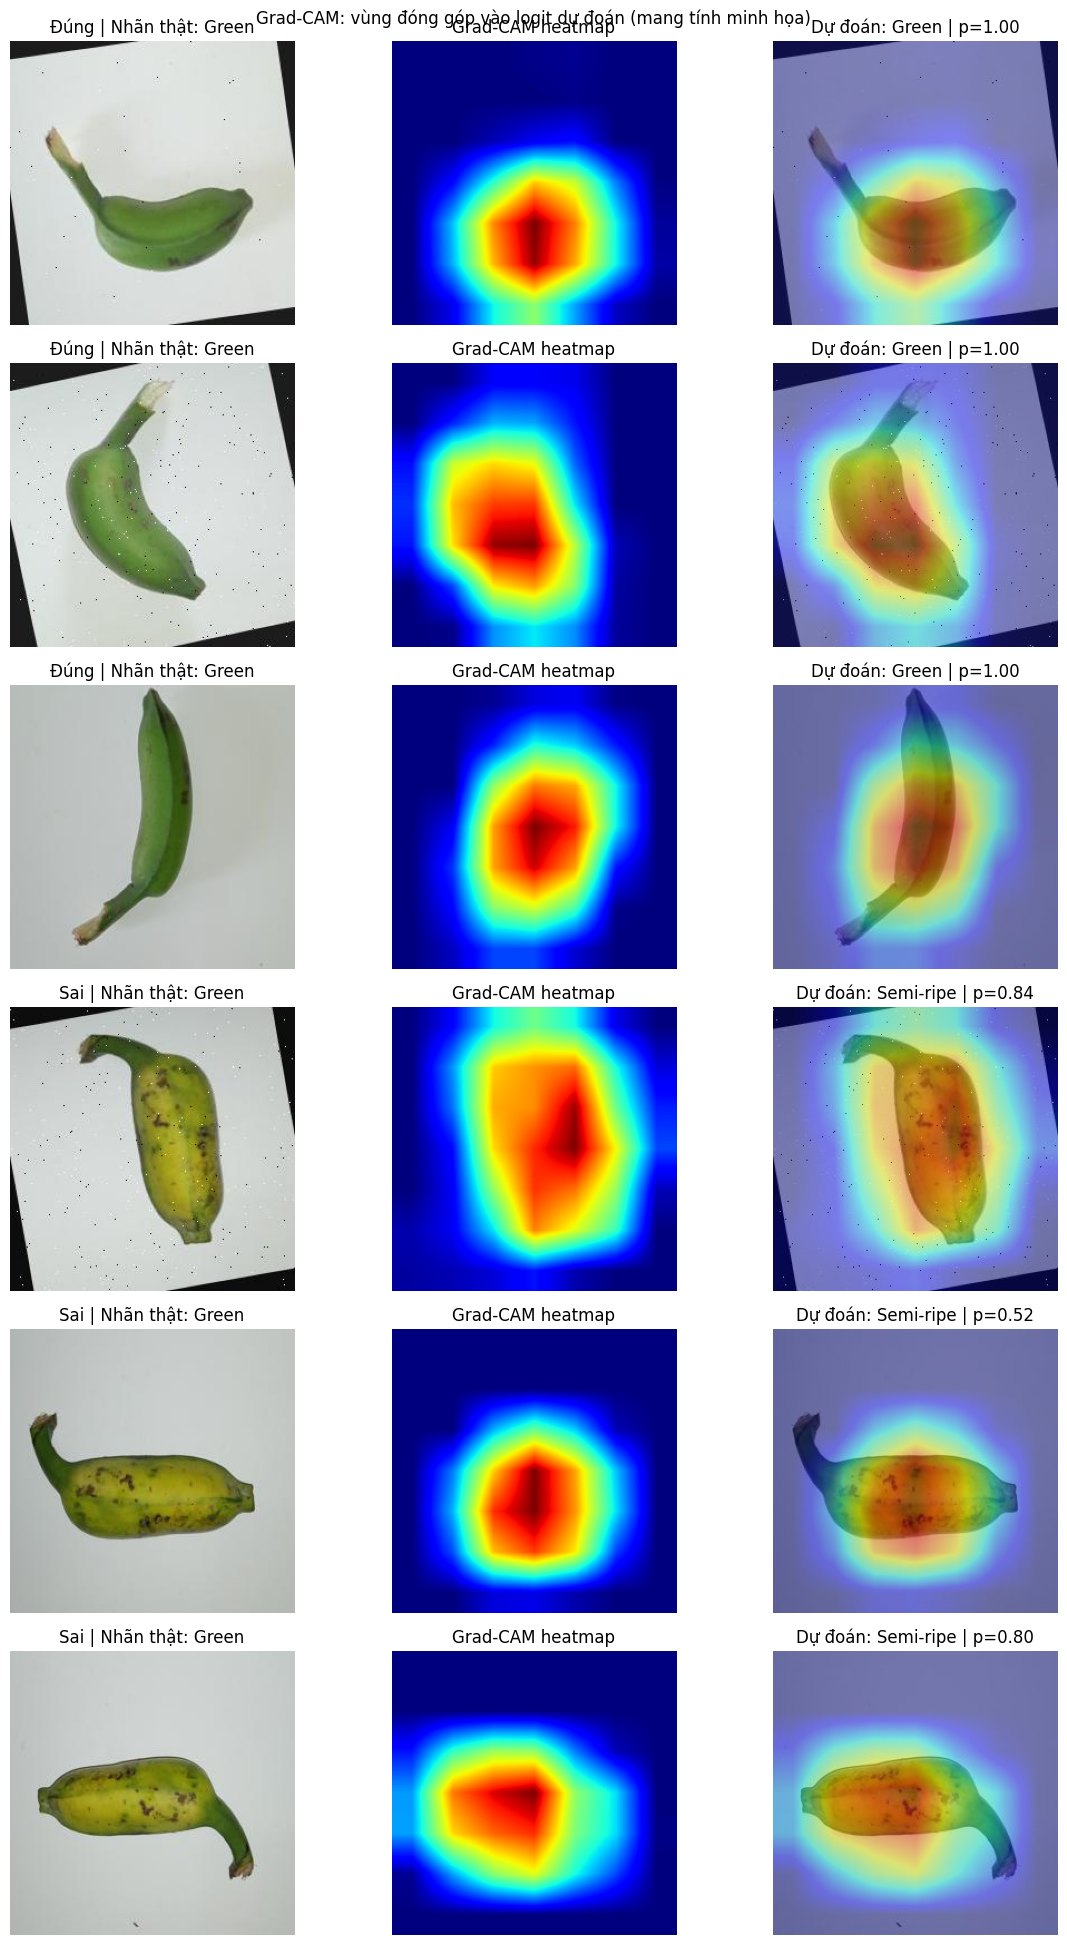

,path,status,true,predicted,confidence
0,/kaggle/input/datasets/thinhng04/banana-datase...,Đúng,Green,Green,0.999929
1,/kaggle/input/datasets/thinhng04/banana-datase...,Đúng,Green,Green,0.999994
2,/kaggle/input/datasets/thinhng04/banana-datase...,Đúng,Green,Green,0.999971
3,/kaggle/input/datasets/thinhng04/banana-datase...,Sai,Green,Semi-ripe,0.837052
4,/kaggle/input/datasets/thinhng04/banana-datase...,Sai,Green,Semi-ripe,0.522125
5,/kaggle/input/datasets/thinhng04/banana-datase...,Sai,Green,Semi-ripe,0.798843


In [10]:
def compute_gradcam(model, sample_path, target_class=None):
    model.eval()
    # Hook ra tensor activation, sau đó attach tensor.register_hook cho gradient:
    # tránh xung đột backward hook với các activation inplace trong CNN.
    cache = {}
    def forward_hook(module, inputs, outputs):
        cache['activation'] = outputs
        outputs.register_hook(lambda grad: cache.__setitem__('gradient', grad))
    handle = model.features[-1].register_forward_hook(forward_hook)
    try:
        with Image.open(sample_path) as image:
            rgb = image.convert('RGB')
        tensor = base_tf(rgb).unsqueeze(0).to(DEVICE)
        model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits = model(tensor)
            prob = torch.softmax(logits.detach(), dim=1)[0]
            pred = int(torch.argmax(logits, dim=1).item())
            cls = pred if target_class is None else int(target_class)
            logits[0, cls].backward()
        acts = cache['activation'][0].detach().float()
        grads = cache['gradient'][0].detach().float()
        alpha = grads.mean(dim=(1, 2), keepdim=True)
        heatmap = torch.relu((alpha * acts).sum(dim=0, keepdim=True).unsqueeze(0))
        heatmap = F.interpolate(heatmap, size=(rgb.height, rgb.width),
                                mode='bilinear', align_corners=False)[0, 0]
        heatmap -= heatmap.min()
        heatmap /= heatmap.max().clamp_min(1e-8)
        return rgb, heatmap.cpu().numpy(), pred, float(prob[pred].item())
    finally:
        handle.remove()

def visualize_gradcam(model, frame, n_correct=GRADCAM_MAX_CORRECT, n_wrong=GRADCAM_MAX_WRONG):
    y_true = np.asarray(mobile_tests[best_mobile_name]['y_true'])
    y_pred = np.asarray(mobile_tests[best_mobile_name]['y_pred'])
    if len(frame) != len(y_true):
        raise RuntimeError('Thứ tự hoặc số ảnh test không khớp với predictions.')
    correct_indices = np.where(y_true == y_pred)[0][:n_correct].tolist()
    wrong_indices = np.where(y_true != y_pred)[0][:n_wrong].tolist()
    chosen = [('Đúng', i) for i in correct_indices] + [('Sai', i) for i in wrong_indices]
    if not chosen:
        raise RuntimeError('Không có ảnh nào để hiển thị Grad-CAM.')
    if not wrong_indices:
        print('Mô hình không dự đoán sai trên test hiện tại; chỉ vẽ ví dụ đúng.')

    fig, axes = plt.subplots(len(chosen), 3, figsize=(12.2, 3.3 * len(chosen)), squeeze=False)
    report_rows = []
    for row_idx, (status, image_idx) in enumerate(chosen):
        sample = frame.iloc[image_idx]
        original, heatmap, predicted, confidence = compute_gradcam(model, sample.path)
        rgb_np = np.asarray(original)
        color_map = plt.get_cmap('jet')(heatmap)[..., :3]
        overlay = np.clip(rgb_np / 255.0 * 0.56 + color_map * 0.44, 0, 1)
        axes[row_idx, 0].imshow(original)
        axes[row_idx, 0].set_title(f'{status} | Nhãn thật: {sample.class_name}')
        axes[row_idx, 1].imshow(heatmap, cmap='jet', vmin=0, vmax=1)
        axes[row_idx, 1].set_title('Grad-CAM heatmap')
        axes[row_idx, 2].imshow(overlay)
        axes[row_idx, 2].set_title(f'Dự đoán: {class_names[predicted]} | p={confidence:.2f}')
        for ax in axes[row_idx]:
            ax.axis('off')
        report_rows.append({'path': sample.path, 'status': status, 'true': sample.class_name,
                            'predicted': class_names[predicted], 'confidence': confidence})
    fig.suptitle('Grad-CAM: vùng đóng góp vào logit dự đoán (mang tính minh họa)')
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / 'figures' / '10_gradcam_correct_wrong.png', dpi=170, bbox_inches='tight')
    plt.show()
    return pd.DataFrame(report_rows)

gradcam_report = visualize_gradcam(infer_model, test_df)
gradcam_report.to_csv(OUTPUT_DIR / 'reports' / 'gradcam_examples.csv', index=False)
display(gradcam_report)

## 11. Ablation Study — giữ nguyên checkpoint, bỏ thông tin màu RGB → grayscale

**Chỉ thay ảnh đầu vào**, không huấn luyện lại, không đổi tập test hoặc trọng số; biến đổi thành ảnh xám ba kênh để vẫn phù hợp MobileNetV2. So sánh Accuracy/F1-Macro tổng thể và F1 theo từng lớp. Nếu điểm số giảm sau grayscale, đây là dấu hiệu mô hình nhạy với việc thiếu thông tin màu; **không thể kết luận nó dùng HSV một cách tường minh**. Kết quả chịu ảnh hưởng bởi sự khác biệt phân phối dữ liệu (*distribution shift*).

=== ABLATION: RGB SO VỚI GRAYSCALE (CÙNG CHECKPOINT) ===


,Đầu vào,Test Accuracy,Test F1-Macro,Số ảnh
0,RGB gốc,0.9526,0.9525,359
1,Grayscale (3 kênh),0.4067,0.3386,359


Δ Accuracy (Grayscale - RGB) = -0.546
Δ F1-Macro (Grayscale - RGB) = -0.6139


,class_name,RGB F1,Grayscale F1,Δ F1 (Gray-RGB)
0,Green,0.978,0.082,-0.897
1,Overripe,0.994,0.499,-0.496
2,Ripe,0.930,0.513,-0.417
3,Semi-ripe,0.907,0.261,-0.646


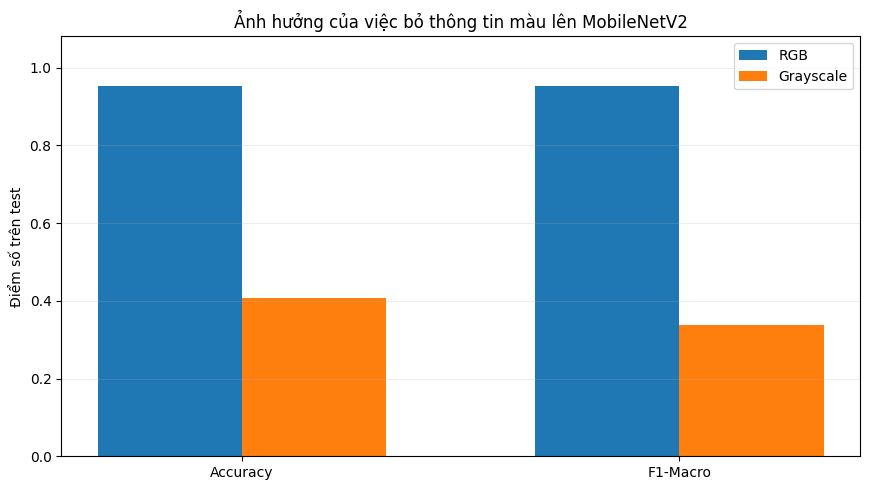

Số ảnh đổi dự đoán giữa RGB và grayscale: 211


In [11]:
# Không đổi data split, nhãn, checkpoint hay preprocessing ImageNet cuối cùng.
grayscale_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    NORMALIZE
])
gray_test_loader = make_loader(test_df, grayscale_tf, shuffle=False)
criterion = nn.CrossEntropyLoss()
with torch.inference_mode():
    gray_test = run_epoch(infer_model, gray_test_loader, criterion)
    rgb_test = run_epoch(infer_model, test_loader, criterion)

ablation_rows = [
    {'Đầu vào': 'RGB gốc', 'Test Accuracy': rgb_test['accuracy'],
     'Test F1-Macro': rgb_test['f1_macro'], 'Số ảnh': len(test_df)},
    {'Đầu vào': 'Grayscale (3 kênh)', 'Test Accuracy': gray_test['accuracy'],
     'Test F1-Macro': gray_test['f1_macro'], 'Số ảnh': len(test_df)}
]
ablation_df = pd.DataFrame(ablation_rows)
ablation_df.to_csv(OUTPUT_DIR / 'reports' / 'rgb_vs_grayscale_ablation.csv', index=False)
print('=== ABLATION: RGB SO VỚI GRAYSCALE (CÙNG CHECKPOINT) ===')
display(ablation_df.style.format({'Test Accuracy': '{:.4f}', 'Test F1-Macro': '{:.4f}'}))
print('Δ Accuracy (Grayscale - RGB) =', round(gray_test['accuracy'] - rgb_test['accuracy'], 4))
print('Δ F1-Macro (Grayscale - RGB) =', round(gray_test['f1_macro'] - rgb_test['f1_macro'], 4))

from sklearn.metrics import f1_score as f1_metric
per_class = pd.DataFrame({
    'class_name': class_names,
    'RGB F1': f1_metric(rgb_test['y_true'], rgb_test['y_pred'],
                        labels=np.arange(len(class_names)), average=None, zero_division=0),
    'Grayscale F1': f1_metric(gray_test['y_true'], gray_test['y_pred'],
                              labels=np.arange(len(class_names)), average=None, zero_division=0)
})
per_class['Δ F1 (Gray-RGB)'] = per_class['Grayscale F1'] - per_class['RGB F1']
per_class.to_csv(OUTPUT_DIR / 'reports' / 'ablation_per_class_f1.csv', index=False)
display(per_class.style.format({'RGB F1':'{:.3f}', 'Grayscale F1':'{:.3f}', 'Δ F1 (Gray-RGB)':'{:+.3f}'}))

fig, ax = plt.subplots(figsize=(8.8, 5.0))
x = np.arange(2)
width = 0.33
rgb_vals = ablation_df.iloc[0][['Test Accuracy', 'Test F1-Macro']].to_numpy(dtype=float)
gray_vals = ablation_df.iloc[1][['Test Accuracy', 'Test F1-Macro']].to_numpy(dtype=float)
ax.bar(x - width / 2, rgb_vals, width, label='RGB')
ax.bar(x + width / 2, gray_vals, width, label='Grayscale')
ax.set_xticks(x, ['Accuracy', 'F1-Macro'])
ax.set_ylabel('Điểm số trên test')
ax.set_ylim(0, 1.08)
ax.set_title('Ảnh hưởng của việc bỏ thông tin màu lên MobileNetV2')
ax.legend()
ax.grid(axis='y', alpha=0.22)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'figures' / '11_rgb_vs_grayscale.png', dpi=170, bbox_inches='tight')
plt.show()

# Bộ dự đoán cho từng ảnh giúp kiểm tra ví dụ mô hình đổi dự đoán sau biến đổi.
ablation_predictions = test_df[['path', 'class_name', 'label']].copy()
ablation_predictions['rgb_prediction'] = [class_names[i] for i in rgb_test['y_pred']]
ablation_predictions['grayscale_prediction'] = [class_names[i] for i in gray_test['y_pred']]
ablation_predictions['prediction_changed'] = ablation_predictions.rgb_prediction != ablation_predictions.grayscale_prediction
ablation_predictions.to_csv(OUTPUT_DIR / 'reports' / 'ablation_predictions.csv', index=False)
meta['rgb_vs_grayscale'] = ablation_rows
meta['changed_predictions_rgb_gray'] = int(ablation_predictions.prediction_changed.sum())
(OUTPUT_DIR / 'run_metadata.json').write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding='utf8')
print('Số ảnh đổi dự đoán giữa RGB và grayscale:', int(ablation_predictions.prediction_changed.sum()))

## 12. Xuất đầy đủ checkpoint, báo cáo và hình ảnh thành một ZIP

Toàn bộ biểu đồ giải thích mô hình và bảng ablation được lưu cùng `checkpoints/mobilenetv2_best_overall.pth`. Không bao gồm dữ liệu ảnh gốc để tránh ZIP quá lớn.

## 12.1. Đóng gói kết quả để tải từ Kaggle Output

In [12]:
SUMMARY_PATH = OUTPUT_DIR/'README_results.txt'
SUMMARY_PATH.write_text(
    'BANANA RIPENESS CLASSIFICATION - EXPERIMENT RESULTS\n'
    f'Dataset: https://data.mendeley.com/datasets/ptfscwtnyz/2\n'
    f'Labels detected from folders: {class_names}\n'
    f'Train/val/test: {len(train_df)}/{len(val_df)}/{len(test_df)}\n'
    f'Split strategy: {SPLIT_STRATEGY}\n'
    f'Grouping method: {GROUPING_METHOD}\n'
    f'Suspicious cross-split near-hash pairs: {near_count}\n'
    f'Grad-CAM examples: {len(gradcam_report)}\n'
    f'RGB/Grayscale ablation accuracy: {rgb_test["accuracy"]:.4f} / {gray_test["accuracy"]:.4f}\n'
    f'Best MobileNetV2 based on validation F1: {best_mobile_name}\n'
    f'MobileNetV2 best checkpoint: checkpoints/mobilenetv2_best_overall.pth\n'
    'IMPORTANT: Hash-based grouping does not prove original-source separation.\n',
    encoding='utf8'
)
ARCHIVE_PATH = WORK_ROOT/'banana_mobilenetv2_results.zip'
with zipfile.ZipFile(ARCHIVE_PATH,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=4) as archive:
    for file in OUTPUT_DIR.rglob('*'):
        if file.is_file():
            archive.write(file,arcname=str(Path(OUTPUT_DIR.name)/file.relative_to(OUTPUT_DIR)))
print('ĐÃ LƯU THÀNH CÔNG:')
print('Thư mục:', OUTPUT_DIR)
print('File ZIP:',ARCHIVE_PATH)
print('Best checkpoint:',best_overall_path)
print('Đường dẫn cần tải sau Save Version: Output → banana_mobilenetv2_results.zip')
print('\nDanh sách file:')
for file in sorted(OUTPUT_DIR.rglob('*')):
    if file.is_file(): print(' •',file.relative_to(OUTPUT_DIR))

ĐÃ LƯU THÀNH CÔNG:
Thư mục: /kaggle/working/banana_mobilenetv2_results
File ZIP: /kaggle/working/banana_mobilenetv2_results.zip
Best checkpoint: /kaggle/working/banana_mobilenetv2_results/checkpoints/mobilenetv2_best_overall.pth
Đường dẫn cần tải sau Save Version: Output → banana_mobilenetv2_results.zip

Danh sách file:
 • README_results.txt
 • checkpoints/mobilenet_1_best.pth
 • checkpoints/mobilenet_2_best.pth
 • checkpoints/mobilenet_3_best.pth
 • checkpoints/mobilenetv2_best_overall.pth
 • data_split_manifest.csv
 • figures/01_class_samples.png
 • figures/04_mobilenet_accuracy.png
 • figures/05_mobilenet_loss.png
 • figures/06_best_mobilenet_confusion_matrix.png
 • figures/07_mobilenet_comparison.png
 • figures/08_inference_samples.png
 • figures/09_feature_maps.png
 • figures/10_gradcam_correct_wrong.png
 • figures/11_rgb_vs_grayscale.png
 • mobilenet_comparison.csv
 • mobilenet_summary.csv
 • reports/ablation_per_class_f1.csv
 • reports/ablation_predictions.csv
 • reports/feature

## 13. Kiến thức và cách giải thích khi bảo vệ đồ án

**1. MobileNetV2 học đặc trưng gì?** Backbone CNN học các biểu diễn (feature maps) qua convolution/depthwise convolution/pointwise convolution, không có cam kết mỗi channel tương ứng HSV hay HOG. `09_feature_maps.png` cho thấy kích hoạt ở các tầng; `10_gradcam_correct_wrong.png` chỉ ra vùng ảnh có đóng góp đến logit dự đoán.

**2. Tại sao chọn MobileNetV2?** Mạng CNN tương đối nhẹ, dùng depthwise separable convolution, inverted residual và linear bottleneck; tận dụng pretrained ImageNet để giảm lượng dữ liệu cần huấn luyện. Tránh khẳng định nó luôn chính xác hơn CNN/SVM khác khi chưa chạy đối chứng.

**3. Ba thí nghiệm có cùng đặc trưng không?** MobileNet 1 dùng backbone đóng băng, MobileNet 2/3 fine-tune các block cuối. Do đó các vector đặc trưng **có thể thay đổi** khi fine-tuning; augmentation là chiến lược huấn luyện, không phải đặc trưng thủ công.

**4. RGB → grayscale cho thấy gì?** Mức độ nhạy với việc loại bỏ thông tin màu của mô hình đã huấn luyện. Đây là *ablation study*, không trực tiếp chứng minh đặc trưng HSV.

**5. Có leakage không?** ZIP augmented có nguy cơ chứa ảnh cùng nguồn ở nhiều biến thể. Notebook dùng group splitting theo ID nguồn (nếu được cung cấp) hoặc heuristic dựa trên filename/hash. Cần xem `reports/split_leakage_audit.csv` và `run_metadata.json`. Với heuristic, không thể đảm bảo tuyệt đối; cách nghiêm ngặt là xin ảnh gốc, chia theo source ID rồi mới augmentation tập train.

**6. Chọn checkpoint bằng gì?** Validation F1-Macro tốt nhất, vì F1-Macro cân bằng ảnh hưởng giữa các lớp. Tập test dùng cho đánh giá cuối, không dùng chọn checkpoint.

**7. Giới hạn của Grad-CAM?** Bản đồ nhiệt trực quan hóa vùng ảnh liên quan đến logit; không tương đương bằng chứng nhân quả hay một bộ mô tả đặc trưng chính xác.

**File cần nộp:** `banana_mobilenetv2_results.zip` và notebook này. **Best checkpoint:** `banana_mobilenetv2_results/checkpoints/mobilenetv2_best_overall.pth` trong ZIP.